In [ ]:
from pathlib import Path
from itertools import product

import numpy as np
import pandas as pd

try:
    _IN_IPYTHON = get_ipython() is not None
except NameError:
    _IN_IPYTHON = False

if not _IN_IPYTHON:
    import matplotlib
    matplotlib.use('Agg')

import matplotlib.pyplot as plt

try:
    from IPython.display import display
except ImportError:
    def display(*args, **kwargs):
        return None

RESULTS_ROOT_OVERRIDE = None
SAVE_FIGURES = True
FIGURE_DIR_NAME = 'paper_figures'

plt.rcParams.update({
    'font.family': 'CMU Serif',
    'axes.labelsize': 9,
    'axes.titlesize': 9,
    'xtick.labelsize': 8,
    'ytick.labelsize': 8,
    'legend.fontsize': 8,
    'axes.unicode_minus': False,
})

SINGLE_FIGSIZE = (3.0, 2.0)
WIDE_FIGSIZE = (6.4, 2.2)
MULTIPANEL_FIGSIZE = (6.4, 4.2)
COORD_ORDER = ['FD', 'SD', 'CE', 'DA']
COORD_COLORS = {'FD': '#666666', 'SD': '#999999', 'CE': '#b3b3b3', 'DA': '#ffffff'}
COORD_HATCHES = {'FD': '', 'SD': '', 'CE': '', 'DA': 'ooo'}
EDGE_COLOR = '#222222'
GRID_COLOR = '#bdbdbd'
LINE_COLORS = ['#222222', '#555555', '#888888', '#b3b3b3', '#d0d0d0']
LINE_STYLES = ['-', '--', ':', '-.']
MARKERS = ['o', 's', '^', 'D', 'v']


def result_root_candidates():
    cwd = Path.cwd()
    candidates = []
    if RESULTS_ROOT_OVERRIDE is not None:
        candidates.append(Path(RESULTS_ROOT_OVERRIDE))
    candidates.extend([
        cwd,
        cwd / 'Paper Results',
        cwd.parent / 'Paper Results',
        Path.home() / 'Desktop' / 'COORDINATE-2.0' / 'Paper Results',
        Path.home() / 'Desktop' / 'Paper Results',
    ])
    unique = []
    for candidate in candidates:
        candidate = candidate.expanduser().resolve()
        if candidate not in unique:
            unique.append(candidate)
    return unique


def find_results_root(required_any=(), required_all=()):
    checked = []
    for root in result_root_candidates():
        checked.append(root)
        if not root.exists():
            continue
        has_any = True if not required_any else any((root / path).exists() for path in required_any)
        has_all = all((root / path).exists() for path in required_all)
        if has_any and has_all:
            return root
    raise FileNotFoundError('Could not find result files. Checked: ' + ', '.join(str(path) for path in checked))


def style_axes(ax, grid_axis='y'):
    ax.set_axisbelow(True)
    if grid_axis:
        ax.grid(axis=grid_axis, linestyle=':', linewidth=0.5, color=GRID_COLOR)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)


def coord_color(label):
    return COORD_COLORS.get(str(label), '#b3b3b3')


def coord_hatch(label):
    return COORD_HATCHES.get(str(label), '')


def apply_hatches(bars, labels):
    for bar, label in zip(bars, labels):
        label = str(label)
        bar.set_facecolor(coord_color(label))
        bar.set_edgecolor(EDGE_COLOR)
        bar.set_linewidth(0.5)
        bar.set_hatch(coord_hatch(label))


def plot_coord_bars(ax, labels, values, width=0.72):
    labels = [str(label) for label in labels]
    x = np.arange(len(labels))
    bars = ax.bar(x, values, width=width)
    apply_hatches(bars, labels)
    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    style_axes(ax, grid_axis='y')
    return bars


def style_pandas_bar_containers(ax, labels):
    for container, label in zip(ax.containers, labels):
        for patch in container.patches:
            patch.set_facecolor(coord_color(label))
            patch.set_edgecolor(EDGE_COLOR)
            patch.set_linewidth(0.5)
            patch.set_hatch(coord_hatch(label))
    style_axes(ax, grid_axis='y')


def save_or_show(fig, root, filename=None):
    if SAVE_FIGURES and filename:
        out_dir = root / FIGURE_DIR_NAME
        out_dir.mkdir(parents=True, exist_ok=True)
        fig.savefig(out_dir / filename, bbox_inches='tight')
    if _IN_IPYTHON:
        plt.show()
    else:
        plt.close(fig)

ROOT = find_results_root(required_all=[Path('RQ1/runs.csv')])
rq1_dir = ROOT / 'RQ1'
runs_path = rq1_dir / 'runs.csv'

runs = pd.read_csv(runs_path)
if 'status' in runs.columns:
    runs = runs[runs['status'].fillna('ok') == 'ok'].copy()
else:
    runs = runs.copy()

numeric_cols = [
    'avg_latency_s', 'p95_latency_s', 'completion_rate', 'throughput_per_hour',
    'delivered', 'switch_count', 'item_spawning_time', 'n_robots', 'malicious_ratio',
    'fail_prob', 'msg_loss_prob', 'rep', 'event_count', 'wall_time_s',
]
for col in numeric_cols:
    if col in runs.columns:
        runs[col] = pd.to_numeric(runs[col], errors='coerce')

coord_order = [label for label in ['FD', 'SD', 'CE', 'DA'] if label in set(runs['coord_label'].astype(str))]
runs['coord_label'] = pd.Categorical(runs['coord_label'].astype(str), categories=coord_order, ordered=True)

summary = (
    runs.groupby('coord_label', observed=False)
    .agg(
        avg_latency_h=('avg_latency_s', lambda values: values.mean() / 3600),
        p95_latency_h=('p95_latency_s', lambda values: values.mean() / 3600),
        completion_rate_pct=('completion_rate', lambda values: values.mean() * 100),
        delivered_tasks=('delivered', 'mean'),
        throughput_per_hour=('throughput_per_hour', 'mean'),
        switches_per_run=('switch_count', 'mean'),
    )
    .reindex(coord_order)
    .reset_index()
)
labels = summary['coord_label'].astype(str).tolist()

rq1_table = summary[[
    'coord_label', 'completion_rate_pct', 'delivered_tasks',
    'throughput_per_hour', 'switches_per_run',
]].rename(columns={
    'coord_label': 'Mechanism',
    'completion_rate_pct': 'Completion rate (%)',
    'delivered_tasks': 'Delivered tasks (avg)',
    'throughput_per_hour': 'Throughput (tasks/h)',
    'switches_per_run': 'Switches/run',
})
rq1_table['Completion rate (%)'] = rq1_table['Completion rate (%)'].round(2)
rq1_table['Delivered tasks (avg)'] = rq1_table['Delivered tasks (avg)'].round(1)
rq1_table['Throughput (tasks/h)'] = rq1_table['Throughput (tasks/h)'].round(2)
rq1_table['Switches/run'] = rq1_table['Switches/run'].round(1)

fig, axes = plt.subplots(1, 2, figsize=(6.4, 2.45))
plot_coord_bars(axes[0], labels, summary['avg_latency_h'].to_numpy())
axes[0].set_xlabel('Mechanism')
axes[0].set_ylabel('Average task latency (h)')
plot_coord_bars(axes[1], labels, summary['p95_latency_h'].to_numpy())
axes[1].set_xlabel('Mechanism')
axes[1].set_ylabel('P95 task latency (h)')
fig.tight_layout()
save_or_show(fig, ROOT, 'rq1_effectiveness_by_mechanism.pdf')

display(rq1_table)


In [ ]:
from pathlib import Path
from itertools import product

import numpy as np
import pandas as pd

try:
    _IN_IPYTHON = get_ipython() is not None
except NameError:
    _IN_IPYTHON = False

if not _IN_IPYTHON:
    import matplotlib
    matplotlib.use('Agg')

import matplotlib.pyplot as plt

try:
    from IPython.display import display
except ImportError:
    def display(*args, **kwargs):
        return None

RESULTS_ROOT_OVERRIDE = None
SAVE_FIGURES = True
FIGURE_DIR_NAME = 'paper_figures'

plt.rcParams.update({
    'font.family': 'CMU Serif',
    'axes.labelsize': 9,
    'axes.titlesize': 9,
    'xtick.labelsize': 8,
    'ytick.labelsize': 8,
    'legend.fontsize': 8,
    'axes.unicode_minus': False,
})

SINGLE_FIGSIZE = (3.0, 2.0)
WIDE_FIGSIZE = (6.4, 2.2)
MULTIPANEL_FIGSIZE = (6.4, 4.2)
COORD_ORDER = ['FD', 'SD', 'CE', 'DA']
COORD_COLORS = {'FD': '#666666', 'SD': '#999999', 'CE': '#b3b3b3', 'DA': '#ffffff'}
COORD_HATCHES = {'FD': '', 'SD': '', 'CE': '', 'DA': 'ooo'}
EDGE_COLOR = '#222222'
GRID_COLOR = '#bdbdbd'
LINE_COLORS = ['#222222', '#555555', '#888888', '#b3b3b3', '#d0d0d0']
LINE_STYLES = ['-', '--', ':', '-.']
MARKERS = ['o', 's', '^', 'D', 'v']


def result_root_candidates():
    cwd = Path.cwd()
    candidates = []
    if RESULTS_ROOT_OVERRIDE is not None:
        candidates.append(Path(RESULTS_ROOT_OVERRIDE))
    candidates.extend([
        cwd,
        cwd / 'Paper Results',
        cwd.parent / 'Paper Results',
        Path.home() / 'Desktop' / 'COORDINATE-2.0' / 'Paper Results',
        Path.home() / 'Desktop' / 'Paper Results',
    ])
    unique = []
    for candidate in candidates:
        candidate = candidate.expanduser().resolve()
        if candidate not in unique:
            unique.append(candidate)
    return unique


def find_results_root(required_any=(), required_all=()):
    checked = []
    for root in result_root_candidates():
        checked.append(root)
        if not root.exists():
            continue
        has_any = True if not required_any else any((root / path).exists() for path in required_any)
        has_all = all((root / path).exists() for path in required_all)
        if has_any and has_all:
            return root
    raise FileNotFoundError('Could not find result files. Checked: ' + ', '.join(str(path) for path in checked))


def style_axes(ax, grid_axis='y'):
    ax.set_axisbelow(True)
    if grid_axis:
        ax.grid(axis=grid_axis, linestyle=':', linewidth=0.5, color=GRID_COLOR)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)


def coord_color(label):
    return COORD_COLORS.get(str(label), '#b3b3b3')


def coord_hatch(label):
    return COORD_HATCHES.get(str(label), '')


def apply_hatches(bars, labels):
    for bar, label in zip(bars, labels):
        label = str(label)
        bar.set_facecolor(coord_color(label))
        bar.set_edgecolor(EDGE_COLOR)
        bar.set_linewidth(0.5)
        bar.set_hatch(coord_hatch(label))


def plot_coord_bars(ax, labels, values, width=0.72):
    labels = [str(label) for label in labels]
    x = np.arange(len(labels))
    bars = ax.bar(x, values, width=width)
    apply_hatches(bars, labels)
    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    style_axes(ax, grid_axis='y')
    return bars


def style_pandas_bar_containers(ax, labels):
    for container, label in zip(ax.containers, labels):
        for patch in container.patches:
            patch.set_facecolor(coord_color(label))
            patch.set_edgecolor(EDGE_COLOR)
            patch.set_linewidth(0.5)
            patch.set_hatch(coord_hatch(label))
    style_axes(ax, grid_axis='y')


def save_or_show(fig, root, filename=None):
    if SAVE_FIGURES and filename:
        out_dir = root / FIGURE_DIR_NAME
        out_dir.mkdir(parents=True, exist_ok=True)
        fig.savefig(out_dir / filename, bbox_inches='tight')
    if _IN_IPYTHON:
        plt.show()
    else:
        plt.close(fig)

ROOT = find_results_root(required_all=[Path('RQ2/runs.csv'), Path('RQ2/switch_timeline.csv')])
rq2 = ROOT / 'RQ2'
runs = pd.read_csv(rq2 / 'runs.csv')
switches = pd.read_csv(rq2 / 'switch_timeline.csv')

if 'status' in runs.columns:
    runs = runs[runs['status'].fillna('ok') == 'ok'].copy()
else:
    runs = runs.copy()

for frame in [runs, switches]:
    for col in ['rep', 'switch_count', 'fd_switch_count', 'sd_switch_count', 'ce_switch_count', 'first_switch_time', 'performance_score']:
        if col in frame.columns:
            frame[col] = pd.to_numeric(frame[col], errors='coerce')

profile_order = ['paper_daily_stress', 'communication_blackout', 'malicious_surge', 'load_fault_recovery']
profile_labels = {
    'paper_daily_stress': 'Daily stress',
    'communication_blackout': 'Comm. blackout',
    'malicious_surge': 'Malicious surge',
    'load_fault_recovery': 'Load/fault recovery',
}
phase_groups = {
    'normal': 'Nominal',
    'calm': 'Nominal',
    'paper_stress': 'Stress',
    'comm_blackout': 'Stress',
    'malicious_surge': 'Stress',
    'load_fault_stress': 'Stress',
    'recovery': 'Recovery',
}
mechanism_order = ['FD', 'SD', 'CE']
phase_order = ['Nominal', 'Stress', 'Recovery']
phase_colors = {'Nominal': '#b3b3b3', 'Stress': '#4d4d4d', 'Recovery': '#808080'}
phase_hatches = {'Nominal': '', 'Stress': '', 'Recovery': '///'}

runs = runs[runs['profile'].isin(profile_order)].copy()
switches = switches[switches['profile'].isin(profile_order)].copy()
runs['profile'] = pd.Categorical(runs['profile'], categories=profile_order, ordered=True)
switches['profile'] = pd.Categorical(switches['profile'], categories=profile_order, ordered=True)

run_counts = runs.groupby('profile', observed=False)['run_id'].nunique().reindex(profile_order).replace(0, np.nan)
mech_counts = switches.pivot_table(
    index='profile', columns='selected_coord_label', values='switch_idx', aggfunc='count', fill_value=0, observed=False,
).reindex(index=profile_order, columns=mechanism_order, fill_value=0)
mech_per_run = mech_counts.div(run_counts, axis=0)

switches['phase_group'] = switches['phase_label'].map(phase_groups).fillna('Other')
phase_counts = switches.pivot_table(
    index='profile', columns='phase_group', values='switch_idx', aggfunc='count', fill_value=0, observed=False,
).reindex(index=profile_order, columns=phase_order, fill_value=0)
phase_per_run = phase_counts.div(run_counts, axis=0)

profile_summary = runs.groupby('profile', observed=False).agg(
    switches_per_run=('switch_count', 'mean'),
    first_switch_h=('first_switch_time', lambda values: values.mean() / 3600),
).reindex(profile_order)
score_at_switch = switches.groupby('profile', observed=False)['performance_score'].mean().reindex(profile_order)

rq2_table = pd.DataFrame({
    'Profile': [profile_labels[p] for p in profile_order],
    'Switches/run': profile_summary['switches_per_run'].round(1).to_numpy(),
    'First switch (h)': profile_summary['first_switch_h'].round(2).to_numpy(),
    'Score at switch': score_at_switch.round(2).to_numpy(),
    'FD switches/run': mech_per_run['FD'].round(1).to_numpy(),
    'SD switches/run': mech_per_run['SD'].round(1).to_numpy(),
    'CE switches/run': mech_per_run['CE'].round(1).to_numpy(),
})

fig, axes = plt.subplots(1, 2, figsize=(6.4, 2.55))
x = np.arange(len(profile_order))
labels = [profile_labels[p] for p in profile_order]

bottom = np.zeros(len(profile_order))
for mechanism in mechanism_order:
    values = mech_per_run[mechanism].fillna(0).to_numpy()
    bars = axes[0].bar(x, values, bottom=bottom, width=0.72, label=mechanism)
    apply_hatches(bars, [mechanism] * len(values))
    bottom += values
axes[0].set_xticks(x)
axes[0].set_xticklabels(labels, rotation=25, ha='right')
axes[0].set_ylabel('Switches/run')
style_axes(axes[0], grid_axis='y')
axes[0].legend(frameon=False, fontsize=7, ncol=3)

bottom = np.zeros(len(profile_order))
for phase in phase_order:
    values = phase_per_run[phase].fillna(0).to_numpy()
    bars = axes[1].bar(x, values, bottom=bottom, width=0.72, label=phase)
    for bar in bars:
        bar.set_facecolor(phase_colors[phase])
        bar.set_edgecolor(EDGE_COLOR)
        bar.set_linewidth(0.5)
        bar.set_hatch(phase_hatches[phase])
    bottom += values
axes[1].set_xticks(x)
axes[1].set_xticklabels(labels, rotation=25, ha='right')
axes[1].set_ylabel('Switches/run')
style_axes(axes[1], grid_axis='y')
axes[1].legend(frameon=False, fontsize=7, ncol=3)

fig.tight_layout()
save_or_show(fig, ROOT, 'rq2_dynamic_reaction.pdf')
display(rq2_table)


In [ ]:
from pathlib import Path
from itertools import product

import numpy as np
import pandas as pd

try:
    _IN_IPYTHON = get_ipython() is not None
except NameError:
    _IN_IPYTHON = False

if not _IN_IPYTHON:
    import matplotlib
    matplotlib.use('Agg')

import matplotlib.pyplot as plt

try:
    from IPython.display import display
except ImportError:
    def display(*args, **kwargs):
        return None

RESULTS_ROOT_OVERRIDE = None
SAVE_FIGURES = True
FIGURE_DIR_NAME = 'paper_figures'

plt.rcParams.update({
    'font.family': 'CMU Serif',
    'axes.labelsize': 9,
    'axes.titlesize': 9,
    'xtick.labelsize': 8,
    'ytick.labelsize': 8,
    'legend.fontsize': 8,
    'axes.unicode_minus': False,
})

SINGLE_FIGSIZE = (3.0, 2.0)
WIDE_FIGSIZE = (6.4, 2.2)
MULTIPANEL_FIGSIZE = (6.4, 4.2)
COORD_ORDER = ['FD', 'SD', 'CE', 'DA']
COORD_COLORS = {'FD': '#666666', 'SD': '#999999', 'CE': '#b3b3b3', 'DA': '#ffffff'}
COORD_HATCHES = {'FD': '', 'SD': '', 'CE': '', 'DA': 'ooo'}
EDGE_COLOR = '#222222'
GRID_COLOR = '#bdbdbd'
LINE_COLORS = ['#222222', '#555555', '#888888', '#b3b3b3', '#d0d0d0']
LINE_STYLES = ['-', '--', ':', '-.']
MARKERS = ['o', 's', '^', 'D', 'v']


def result_root_candidates():
    cwd = Path.cwd()
    candidates = []
    if RESULTS_ROOT_OVERRIDE is not None:
        candidates.append(Path(RESULTS_ROOT_OVERRIDE))
    candidates.extend([
        cwd,
        cwd / 'Paper Results',
        cwd.parent / 'Paper Results',
        Path.home() / 'Desktop' / 'COORDINATE-2.0' / 'Paper Results',
        Path.home() / 'Desktop' / 'Paper Results',
    ])
    unique = []
    for candidate in candidates:
        candidate = candidate.expanduser().resolve()
        if candidate not in unique:
            unique.append(candidate)
    return unique


def find_results_root(required_any=(), required_all=()):
    checked = []
    for root in result_root_candidates():
        checked.append(root)
        if not root.exists():
            continue
        has_any = True if not required_any else any((root / path).exists() for path in required_any)
        has_all = all((root / path).exists() for path in required_all)
        if has_any and has_all:
            return root
    raise FileNotFoundError('Could not find result files. Checked: ' + ', '.join(str(path) for path in checked))


def style_axes(ax, grid_axis='y'):
    ax.set_axisbelow(True)
    if grid_axis:
        ax.grid(axis=grid_axis, linestyle=':', linewidth=0.5, color=GRID_COLOR)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)


def coord_color(label):
    return COORD_COLORS.get(str(label), '#b3b3b3')


def coord_hatch(label):
    return COORD_HATCHES.get(str(label), '')


def apply_hatches(bars, labels):
    for bar, label in zip(bars, labels):
        label = str(label)
        bar.set_facecolor(coord_color(label))
        bar.set_edgecolor(EDGE_COLOR)
        bar.set_linewidth(0.5)
        bar.set_hatch(coord_hatch(label))


def plot_coord_bars(ax, labels, values, width=0.72):
    labels = [str(label) for label in labels]
    x = np.arange(len(labels))
    bars = ax.bar(x, values, width=width)
    apply_hatches(bars, labels)
    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    style_axes(ax, grid_axis='y')
    return bars


def style_pandas_bar_containers(ax, labels):
    for container, label in zip(ax.containers, labels):
        for patch in container.patches:
            patch.set_facecolor(coord_color(label))
            patch.set_edgecolor(EDGE_COLOR)
            patch.set_linewidth(0.5)
            patch.set_hatch(coord_hatch(label))
    style_axes(ax, grid_axis='y')


def save_or_show(fig, root, filename=None):
    if SAVE_FIGURES and filename:
        out_dir = root / FIGURE_DIR_NAME
        out_dir.mkdir(parents=True, exist_ok=True)
        fig.savefig(out_dir / filename, bbox_inches='tight')
    if _IN_IPYTHON:
        plt.show()
    else:
        plt.close(fig)

ROOT = find_results_root(required_all=[Path('RQ3/runs.csv')])
rq3 = ROOT / 'RQ3'
runs_path = rq3 / 'runs.csv'

runs = pd.read_csv(runs_path)
if 'status' in runs.columns:
    runs = runs[runs['status'].fillna('ok') == 'ok'].copy()
else:
    runs = runs.copy()

numeric_cols = [
    'rep', 'item_spawning_time', 'n_robots', 'wall_time_s', 'event_count',
    'events_per_wall_s', 'adapt_checks', 'adapt_overhead_ms_total',
    'adapt_overhead_ms_mean', 'adapt_overhead_ms_p95', 'rtlola_query_ms_mean',
    'scoring_ms_mean', 'adapt_overhead_wall_pct', 'trace_size_mb',
    'overhead_trace_size_mb',
]
for col in numeric_cols:
    if col in runs.columns:
        runs[col] = pd.to_numeric(runs[col], errors='coerce')

runs['coord_label'] = runs['coord_label'].astype(str).str.upper().str.strip()
coord_order = ['CE', 'SD', 'FD', 'DA']
runs = runs[runs['coord_label'].isin(coord_order)].copy()
runs['total_trace_size_mb'] = runs['trace_size_mb'].fillna(0) + runs['overhead_trace_size_mb'].fillna(0)

mechanism_summary = (
    runs.groupby(['coord_label', 'architecture'], as_index=False)
    .agg(
        runs=('run_id', 'count'),
        wall_time_s=('wall_time_s', 'mean'),
        wall_time_s_p95=('wall_time_s', lambda values: values.quantile(0.95)),
        event_count=('event_count', 'mean'),
        total_trace_size_mb=('total_trace_size_mb', 'mean'),
        adapt_checks=('adapt_checks', 'mean'),
        adapt_overhead_ms_mean=('adapt_overhead_ms_mean', 'mean'),
        adapt_overhead_ms_p95=('adapt_overhead_ms_p95', 'mean'),
        rtlola_query_ms_mean=('rtlola_query_ms_mean', 'mean'),
        scoring_ms_mean=('scoring_ms_mean', 'mean'),
        adapt_overhead_wall_pct=('adapt_overhead_wall_pct', 'mean'),
    )
)
mechanism_summary['coord_label'] = pd.Categorical(mechanism_summary['coord_label'], categories=coord_order, ordered=True)
mechanism_summary = mechanism_summary.sort_values('coord_label')

rq3_table = mechanism_summary[[
    'coord_label', 'wall_time_s', 'event_count', 'total_trace_size_mb',
    'adapt_checks', 'adapt_overhead_ms_mean', 'adapt_overhead_wall_pct',
]].rename(columns={
    'coord_label': 'Mechanism',
    'wall_time_s': 'Simulation wall time (s)',
    'event_count': 'Events (avg)',
    'total_trace_size_mb': 'Trace size (MB)',
    'adapt_checks': 'Adapt. checks (avg)',
    'adapt_overhead_ms_mean': 'Overhead/check (ms)',
    'adapt_overhead_wall_pct': 'Overhead share (%)',
})
rq3_table['Simulation wall time (s)'] = rq3_table['Simulation wall time (s)'].round(2)
rq3_table['Events (avg)'] = rq3_table['Events (avg)'].round(0).astype('Int64')
rq3_table['Trace size (MB)'] = rq3_table['Trace size (MB)'].round(2)
rq3_table['Adapt. checks (avg)'] = rq3_table['Adapt. checks (avg)'].round(0).astype('Int64')
rq3_table['Overhead/check (ms)'] = rq3_table['Overhead/check (ms)'].round(2)
rq3_table['Overhead share (%)'] = rq3_table['Overhead share (%)'].round(2)
static_mask = rq3_table['Mechanism'] != 'DA'
rq3_table.loc[static_mask, ['Adapt. checks (avg)', 'Overhead/check (ms)', 'Overhead share (%)']] = pd.NA
rq3_table = rq3_table.astype(object).where(pd.notna(rq3_table), '-')

fig, ax = plt.subplots(1, 1, figsize=(3.3, 2.35))
da = runs[runs['coord_label'] == 'DA'].copy()
if not da.empty:
    overhead = (
        da.groupby(['item_spawning_time', 'n_robots'], as_index=False)
        .agg(overhead_ms=('adapt_overhead_ms_mean', 'mean'))
    )
    spawn_order = [value for value in [150, 120, 90] if value in set(overhead['item_spawning_time'])]
    for idx, spawn in enumerate(spawn_order):
        frame = overhead[overhead['item_spawning_time'] == spawn].sort_values('n_robots')
        ax.plot(
            frame['n_robots'],
            frame['overhead_ms'],
            label=f'$T_{{spawn}}={int(spawn)}$ s',
            color=LINE_COLORS[idx % len(LINE_COLORS)],
            linestyle=LINE_STYLES[idx % len(LINE_STYLES)],
            marker=MARKERS[idx % len(MARKERS)],
            linewidth=1.4,
            markersize=4.0,
        )
    ax.legend(frameon=False, fontsize=8)
else:
    ax.text(0.5, 0.5, 'No DA overhead data', ha='center', va='center')
ax.set_xlabel('$N_{agent}$', fontsize=10)
ax.set_ylabel('Overhead/check (ms)', fontsize=10)
if not da.empty:
    ax.set_xticks(sorted(da['n_robots'].dropna().unique()))
ax.tick_params(axis='both', labelsize=9)
style_axes(ax, grid_axis='y')
fig.tight_layout()
save_or_show(fig, ROOT, 'rq3_runtime_overhead.pdf')
display(rq3_table)

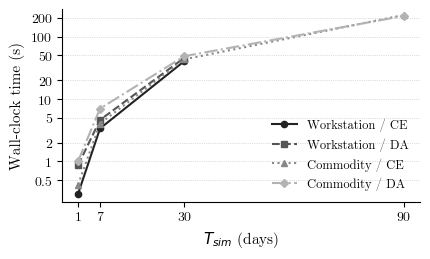

,T_sim (days),Hardware,Mechanism,Peak Memory (MB),Trace size (MB),Events (avg)
2,1,Workstation HW,CE,35.60,0.09,2743
3,1,Workstation HW,DA,37.12,0.15,2669
0,1,Commodity HW,CE,38.13,0.09,2737
1,1,Commodity HW,DA,39.61,0.15,2669
6,7,Workstation HW,CE,39.41,0.63,19072
7,7,Workstation HW,DA,42.84,1.06,18518
4,7,Commodity HW,CE,42.12,0.63,19099
5,7,Commodity HW,DA,46.28,1.06,18518
10,30,Workstation HW,CE,54.29,2.75,81875
11,30,Workstation HW,DA,63.58,4.56,79151


In [1]:
from pathlib import Path
from itertools import product

import numpy as np
import pandas as pd

try:
    _IN_IPYTHON = get_ipython() is not None
except NameError:
    _IN_IPYTHON = False

if not _IN_IPYTHON:
    import matplotlib
    matplotlib.use('Agg')

import matplotlib.pyplot as plt

try:
    from IPython.display import display
except ImportError:
    def display(*args, **kwargs):
        return None

RESULTS_ROOT_OVERRIDE = None
SAVE_FIGURES = True
FIGURE_DIR_NAME = 'paper_figures'

plt.rcParams.update({
    'font.family': 'CMU Serif',
    'axes.labelsize': 9,
    'axes.titlesize': 9,
    'xtick.labelsize': 8,
    'ytick.labelsize': 8,
    'legend.fontsize': 8,
    'axes.unicode_minus': False,
})

SINGLE_FIGSIZE = (3.0, 2.0)
WIDE_FIGSIZE = (6.4, 2.2)
MULTIPANEL_FIGSIZE = (6.4, 4.2)
COORD_ORDER = ['FD', 'SD', 'CE', 'DA']
COORD_COLORS = {'FD': '#666666', 'SD': '#999999', 'CE': '#b3b3b3', 'DA': '#ffffff'}
COORD_HATCHES = {'FD': '', 'SD': '', 'CE': '', 'DA': 'ooo'}
EDGE_COLOR = '#222222'
GRID_COLOR = '#bdbdbd'
LINE_COLORS = ['#222222', '#555555', '#888888', '#b3b3b3', '#d0d0d0']
LINE_STYLES = ['-', '--', ':', '-.']
MARKERS = ['o', 's', '^', 'D', 'v']


def result_root_candidates():
    cwd = Path.cwd()
    candidates = []
    if RESULTS_ROOT_OVERRIDE is not None:
        candidates.append(Path(RESULTS_ROOT_OVERRIDE))
    candidates.extend([
        cwd,
        cwd / 'Paper Results',
        cwd.parent / 'Paper Results',
        Path.home() / 'Desktop' / 'COORDINATE-2.0' / 'Paper Results',
        Path.home() / 'Desktop' / 'Paper Results',
    ])
    unique = []
    for candidate in candidates:
        candidate = candidate.expanduser().resolve()
        if candidate not in unique:
            unique.append(candidate)
    return unique


def find_results_root(required_any=(), required_all=()):
    checked = []
    for root in result_root_candidates():
        checked.append(root)
        if not root.exists():
            continue
        has_any = True if not required_any else any((root / path).exists() for path in required_any)
        has_all = all((root / path).exists() for path in required_all)
        if has_any and has_all:
            return root
    raise FileNotFoundError('Could not find result files. Checked: ' + ', '.join(str(path) for path in checked))


def style_axes(ax, grid_axis='y'):
    ax.set_axisbelow(True)
    if grid_axis:
        ax.grid(axis=grid_axis, linestyle=':', linewidth=0.5, color=GRID_COLOR)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)


def coord_color(label):
    return COORD_COLORS.get(str(label), '#b3b3b3')


def coord_hatch(label):
    return COORD_HATCHES.get(str(label), '')


def apply_hatches(bars, labels):
    for bar, label in zip(bars, labels):
        label = str(label)
        bar.set_facecolor(coord_color(label))
        bar.set_edgecolor(EDGE_COLOR)
        bar.set_linewidth(0.5)
        bar.set_hatch(coord_hatch(label))


def plot_coord_bars(ax, labels, values, width=0.72):
    labels = [str(label) for label in labels]
    x = np.arange(len(labels))
    bars = ax.bar(x, values, width=width)
    apply_hatches(bars, labels)
    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    style_axes(ax, grid_axis='y')
    return bars


def style_pandas_bar_containers(ax, labels):
    for container, label in zip(ax.containers, labels):
        for patch in container.patches:
            patch.set_facecolor(coord_color(label))
            patch.set_edgecolor(EDGE_COLOR)
            patch.set_linewidth(0.5)
            patch.set_hatch(coord_hatch(label))
    style_axes(ax, grid_axis='y')


def save_or_show(fig, root, filename=None):
    if SAVE_FIGURES and filename:
        out_dir = root / FIGURE_DIR_NAME
        out_dir.mkdir(parents=True, exist_ok=True)
        fig.savefig(out_dir / filename, bbox_inches='tight')
    if _IN_IPYTHON:
        plt.show()
    else:
        plt.close(fig)

ROOT = find_results_root(required_all=[Path('RQ4/runs.csv')])
rq4 = ROOT / 'RQ4'
runs_path = rq4 / 'runs.csv'

runs = pd.read_csv(runs_path)
if 'status' in runs.columns:
    runs = runs[runs['status'].fillna('ok') == 'ok'].copy()
else:
    runs = runs.copy()

required_cols = {'coord_label', 'sim_days', 'item_spawning_time', 'n_robots', 'rep'}
missing_cols = sorted(required_cols - set(runs.columns))
if missing_cols:
    raise ValueError(f'RQ4 runs.csv is missing required columns: {missing_cols}')

numeric_cols = [
    'sim_days', 'item_spawning_time', 'n_robots', 'rep', 'wall_time_s', 'event_count',
    'events_per_wall_s', 'max_rss_mb', 'trace_size_mb', 'overhead_trace_size_mb',
    'total_output_size_mb',
]
for col in numeric_cols:
    if col in runs.columns:
        runs[col] = pd.to_numeric(runs[col], errors='coerce')

runs['coord_label'] = runs['coord_label'].astype(str).str.upper().str.strip()
runs = runs[runs['coord_label'].isin(['CE', 'DA'])].copy()
if 'machine_label' in runs.columns:
    raw_machine = runs['machine_label']
else:
    raw_machine = pd.Series('', index=runs.index)
runs['machine_label'] = raw_machine.fillna('').astype(str).str.lower().str.strip()


def hardware_profile(label):
    if label in {'', 'nan', 'none', 'null', 'workstation', 'ws'}:
        return 'Workstation HW'
    if label in {'mac', 'commodity', 'commodity-hardware', 'commodity_hw'}:
        return 'Commodity HW'
    return label.replace('_', ' ').replace('-', ' ').title()

runs['hardware'] = runs['machine_label'].map(hardware_profile)
runs['profile'] = runs['hardware'] + ' / ' + runs['coord_label']
hardware_order = ['Workstation HW', 'Commodity HW']
coord_order = ['CE', 'DA']
profile_order = [f'{hardware} / {coord}' for hardware, coord in product(hardware_order, coord_order)]
profile_labels = {
    'Workstation HW / CE': 'Workstation / CE',
    'Workstation HW / DA': 'Workstation / DA',
    'Commodity HW / CE': 'Commodity / CE',
    'Commodity HW / DA': 'Commodity / DA',
}

summary = (
    runs.groupby(['sim_days', 'hardware', 'coord_label', 'profile'], as_index=False)
    .agg(
        wall_time_s=('wall_time_s', 'mean'),
        event_count=('event_count', 'mean'),
        max_rss_mb=('max_rss_mb', 'mean'),
        total_output_size_mb=('total_output_size_mb', 'mean'),
    )
)
summary['hardware'] = pd.Categorical(summary['hardware'], categories=hardware_order, ordered=True)
summary['coord_label'] = pd.Categorical(summary['coord_label'], categories=coord_order, ordered=True)
summary['profile'] = pd.Categorical(summary['profile'], categories=profile_order, ordered=True)
summary = summary.sort_values(['sim_days', 'hardware', 'coord_label'])

resource_table = summary[[
    'sim_days', 'hardware', 'coord_label',
    'max_rss_mb', 'total_output_size_mb', 'event_count',
]].rename(columns={
    'sim_days': 'T_sim (days)',
    'hardware': 'Hardware',
    'coord_label': 'Mechanism',
    'max_rss_mb': 'Peak Memory (MB)',
    'total_output_size_mb': 'Trace size (MB)',
    'event_count': 'Events (avg)',
})
resource_table['Peak Memory (MB)'] = resource_table['Peak Memory (MB)'].round(2)
resource_table['Trace size (MB)'] = resource_table['Trace size (MB)'].round(2)
resource_table['Events (avg)'] = resource_table['Events (avg)'].round(0).astype('Int64')

sim_days_order = sorted(summary['sim_days'].dropna().unique())
series = {profile: summary[summary['profile'] == profile].set_index('sim_days') for profile in profile_order}
fig, ax = plt.subplots(1, 1, figsize=(4.4, 2.7))
for idx, profile in enumerate(profile_order):
    frame = series.get(profile)
    if frame is None or frame.empty:
        continue
    values = frame['wall_time_s'].reindex(sim_days_order)
    ax.plot(
        sim_days_order,
        values,
        label=profile_labels.get(profile, profile),
        color=LINE_COLORS[idx % len(LINE_COLORS)],
        linestyle=LINE_STYLES[idx % len(LINE_STYLES)],
        marker=MARKERS[idx % len(MARKERS)],
        linewidth=1.5,
        markersize=4.5,
    )
ax.set_xlabel('$T_{sim}$ (days)', fontsize=11)
ax.set_ylabel('Wall-clock time (s)', fontsize=11)
ax.set_yscale('log')
wall_values = summary['wall_time_s'].dropna()
if not wall_values.empty:
    y_min = max(0.1, wall_values.min() * 0.75)
    y_max = wall_values.max() * 1.25
    tick_candidates = np.array([0.2, 0.5, 1, 2, 5, 10, 20, 50, 100, 200, 500, 1000])
    y_ticks = tick_candidates[(tick_candidates >= y_min) & (tick_candidates <= y_max)]
    ax.set_ylim(y_min, y_max)
    ax.set_yticks(y_ticks)
    ax.set_yticklabels([f'{tick:g}' for tick in y_ticks])
    ax.minorticks_off()
ax.set_xticks(sim_days_order)
ax.tick_params(axis='both', labelsize=10)
style_axes(ax, grid_axis='y')
ax.legend(loc='lower right', frameon=False, fontsize=9)
fig.tight_layout()
save_or_show(fig, ROOT, 'rq4_wall_time_scalability.pdf')
display(resource_table)